## Assignment 1.1. Study of Radar Receiver Poor Noise Statistics

### Section 1: Introduction

In this practicum, you will analyze complex-valued radar receiver noise recorded when the radar transmitter was switched off. Under normal operating conditions, thermal noise in a radar receiver can often be modeled as a complex circular Gaussian random process.

The goals of this exercise are:

- Investigate the statistical properties of the measured noise.
- Verify whether the measured data are consistent with a complex Gaussian model.
- Estimate statistical moments from data.
- Derive and compare theoretical probability density functions (PDFs) with empirical distributions.
- Interpret the physical meaning of the observed results.

### Section 2: Data Loading

Copy the dataset zip file into the current directory and unzip it. After that, you will have a subdirectory 'dataset-##', where ## is your group number.

#### Loading and Inspecting the Dataset

The file `NoiseFile.mat` contains complex radar receiver samples collected in the absence of intentional target illumination.

The dataset contains:

- `Data_out`: complex-valued radar samples organized in range-slow-time format.
- `range`: corresponding range axis values.

Before proceeding:

1. Verify the dimensions of the loaded variables.
2. Determine the total number of available samples.
3. Comment on the advantages of using a large dataset when estimating statistical distributions.

In [1]:
from pathlib import Path
from scipy.io import loadmat

noise_file = Path("dataset-01") / "NoiseFile.mat"
noise_data = loadmat(noise_file)
noise_variables = {
    name: value for name, value in noise_data.items() if not name.startswith("__")
}
noise_variables["Data_out"] = noise_variables["Data_out"].T

print(f"Loaded {noise_file}")
for name, value in noise_variables.items():
    print(f"{name}: shape={value.shape}, dtype={value.dtype}")

Loaded dataset-01/NoiseFile.mat
Data_out: shape=(270, 5120), dtype=complex128
range: shape=(1, 270), dtype=float64


### Section 3: Range-Slow-Time Visualization of Noise Amplitude

Visualize the amplitude of the complex noise samples in the range-slow-time domain.

Tasks:

- Display the amplitude in both linear and dB scales.
- Compare the visual appearance of the two representations.
- Identify any visible trends, non-uniformities, or artifacts.
- Discuss whether the noise appears stationary across range and slow time.

_Hint:_ Pure thermal noise should not exhibit persistent structures or localized high-energy regions.

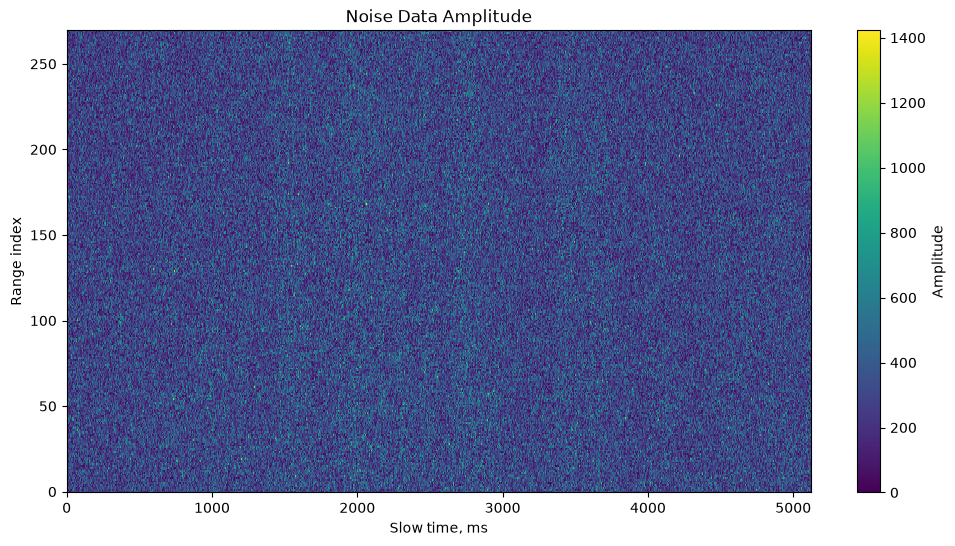

In [3]:
import matplotlib.pyplot as plt
import numpy as np

flag_dB = False  # Set to True to display amplitude in dB, 
                # False for linear scale

amplitudes = np.abs(noise_variables["Data_out"])
label_Amplitude = "Amplitude"

if (flag_dB):
    amplitudes[amplitudes==0] = 1  # Avoid log of zero
    amplitudes = 20.*np.log10(amplitudes)
    label_Amplitude = "Amplitude (dB)"

fig, ax = plt.subplots(figsize=(12, 6))
image = ax.imshow(
    amplitudes,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
)
ax.set(title="Noise Data Amplitude", xlabel="Slow time, ms", ylabel="Range index")
fig.colorbar(image, ax=ax, label=label_Amplitude)
plt.show()

### Section 4: Statistical Analysis of Noise Parameters using Histograms and PDFs

For each of the following quantities:

- Real part
- Imaginary part
- Amplitude
- Phase
- Power

perform the following steps:

1. Compute the sample mean and standard deviation.
2. Plot the empirical histogram using normalized probability density.
3. Determine the theoretical distributions that are expected for listed above Gaussian receiver noise's parameters.
4. Estimate the parameters of the theoretical distribution from measured data.
5. Overlay the theoretical PDF on the histogram.
6. Discuss the agreement between theory and measurements.

Explain why each distribution arises from a complex Gaussian noise model.


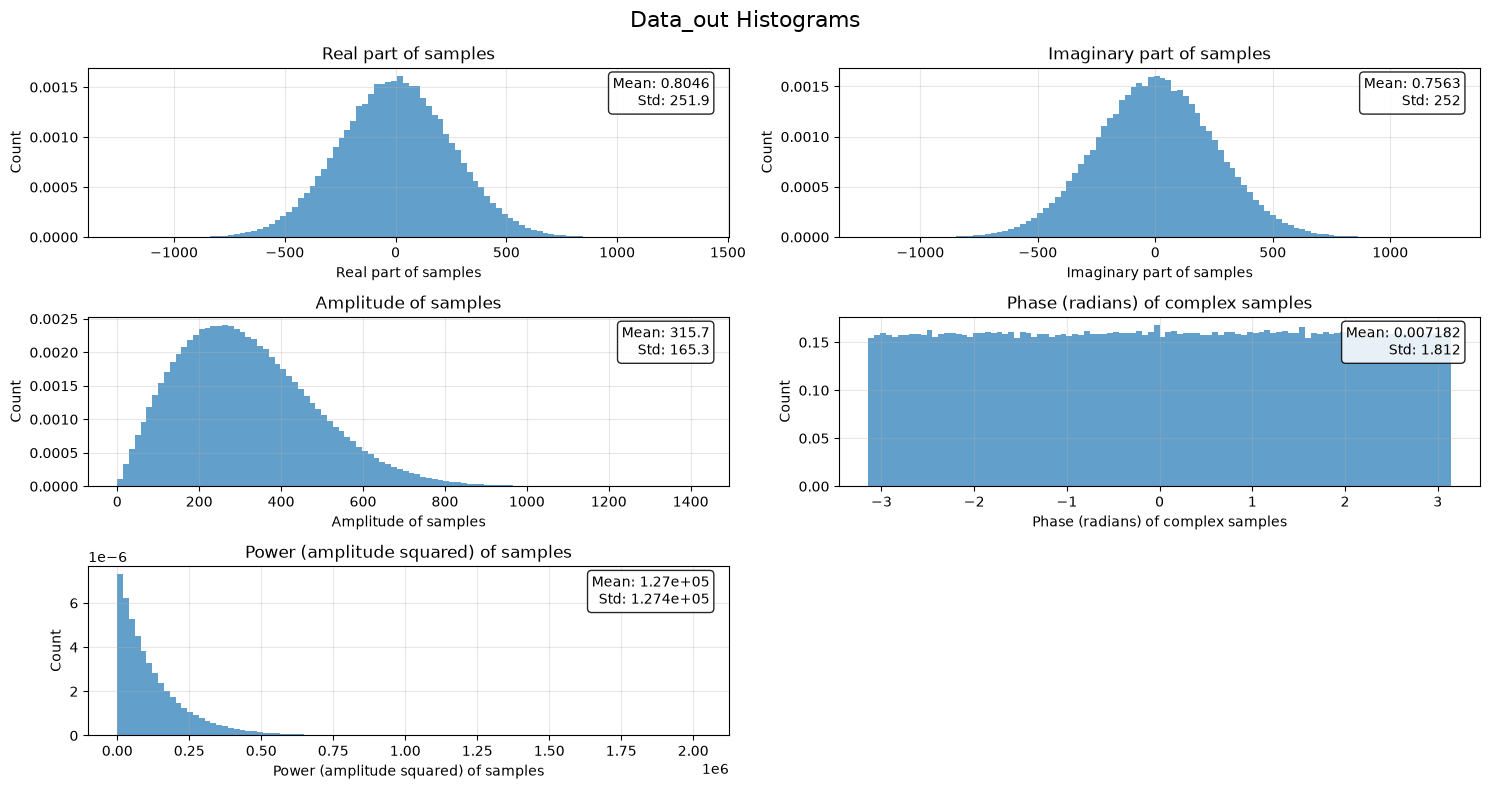

In [7]:
import matplotlib.pyplot as plt
import numpy as np

data_out = noise_variables["Data_out"]
amplitudes = np.abs(data_out)
histogram_values = {
    "Real part of samples": np.real(data_out),
    "Imaginary part of samples": np.imag(data_out),
    "Amplitude of samples": amplitudes,
    "Phase (radians) of complex samples": np.angle(data_out),
    "Power (amplitude squared) of samples": amplitudes**2,
}

fig, axes = plt.subplots(3, 2, figsize=(15, 8))
for ind, (ax, (label, values)) in enumerate(zip(axes.flat, histogram_values.items()), start=1):
    samples = values.ravel()
    counts, bin_edges = np.histogram(samples, bins=100, density=True)
    ax.stairs(counts, bin_edges, fill=True, alpha=0.7)
    ax.set(title=label, xlabel=label, ylabel="Count")
    ax.text(
        0.97,
        0.95,
        f"Mean: {np.mean(samples):.4g}\nStd: {np.std(samples):.4g}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.85},
    )
    ax.grid(True, alpha=0.3)

axes.flat[-1].set_visible(False)
fig.suptitle("Data_out Histograms", fontsize=16)
fig.tight_layout()
plt.show()

### Section 5: Two-Dimensional Histogram of the Joint Distribution of In-phase and Quadrature Components

Construct a two-dimensional histogram of the real and imaginary parts of the complex samples.

Analyze the resulting density plot and answer the following:

- Is the distribution approximately circular?
- Are the real and imaginary components centered around zero?
- Do the components appear statistically independent?
- Is there any indication of correlation between the components?
- Does the observed shape support the assumption of circular complex Gaussian noise?

Relate your observations to the theoretical model of thermal receiver noise.


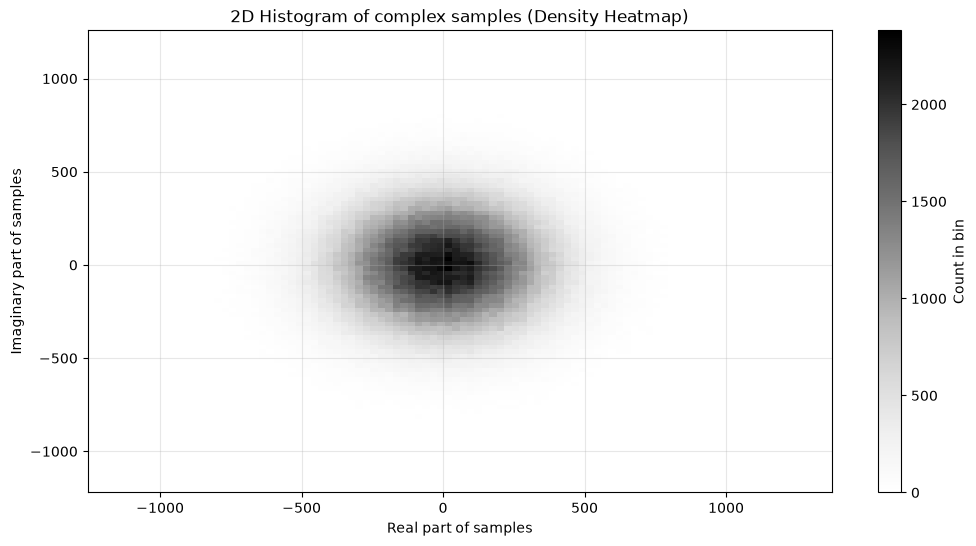

In [8]:
fig, ax = plt.subplots(figsize=(12, 6))
    
plt.hist2d( histogram_values["Real part of samples"].ravel(), 
            histogram_values["Imaginary part of samples"].ravel(), 
            bins=100, cmap="Greys")
plt.colorbar(label="Count in bin")
plt.xlabel("Real part of samples")
plt.ylabel("Imaginary part of samples")
plt.title("2D Histogram of complex samples (Density Heatmap)")
plt.grid(True, alpha=0.3)
plt.show()


---

### Suggested Report Questions

The following questions would make good report requirements.

**Question 1**. Do the measured real and imaginary components follow a Gaussian distribution?

Support your answer by comparing the empirical histograms with the corresponding theoretical Gaussian PDFs and by discussing the estimated mean and standard deviation values.

**Question 2**.Why is the amplitude of complex Gaussian noise expected to follow a Rayleigh distribution?

Provide a mathematical explanation and compare the theoretical Rayleigh PDF with the measured histogram.

**Question 3**. What information can be obtained from the phase histogram?

Discuss why a uniform phase distribution is expected for circular complex Gaussian noise and evaluate whether the measurements support this assumption.

**Question 4**. Does the two-dimensional histogram indicate that the real and imaginary components are independent and identically distributed (i.i.d.)?

Use visual evidence from the 2D histogram and statistical arguments to justify your conclusion.

**Question 5**. To what extent can the measured dataset be modeled as thermal receiver noise?

Summarize all evidence collected from:

- amplitude plots,
- histogram analysis,
- estimated moments,
- theoretical PDF fitting,
- two-dimensional histogram.

State clearly whether the complex Gaussian noise model is validated by the measurements.

---